<a href="https://colab.research.google.com/github/jiminchoi2007/jimin/blob/main/j.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 인천광역시 문화공간 데이터 탐색적 데이터 분석(EDA)

## 1. 데이터 확인 및 정리

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import io

uploaded = files.upload()
file_name = next(iter(uploaded))

# CSV 인코딩 확인
raw = None
for encoding in ['utf-8-sig', 'cp949', 'euc-kr', 'utf-8']:
    try:
        raw = pd.read_csv(io.BytesIO(uploaded[file_name]), encoding=encoding)
        print('사용한 인코딩:', encoding)
        break
    except UnicodeDecodeError:
        pass

if raw is None:
    raise ValueError('CSV 파일의 인코딩을 확인할 수 없습니다.')

data = raw.copy()

for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].astype('string').str.strip()
    data[col] = data[col].replace(r'^\\s*$', pd.NA, regex=True)

print('정제 후 행·열 수:', data.shape)
print('열별 결측치 수')
display(data.isna().sum().to_frame('결측치 수'))
print('완전히 같은 행:', int(data.duplicated().sum()))
if '번호' in data.columns:
    print('번호 중복:', int(data['번호'].duplicated().sum()))
print('자료형')
display(data.dtypes.astype(str).to_frame('자료형'))

Saving 인천광역시_문화공간_20251126.csv to 인천광역시_문화공간_20251126 (1).csv
사용한 인코딩: cp949
정제 후 행·열 수: (940, 7)
열별 결측치 수


,결측치 수
번호,0
공간 구분 이름,0
공간명,0
전화번호,177
팩스번호,538
주소,5
상세주소,696


완전히 같은 행: 0
번호 중복: 0
자료형


,자료형
번호,int64
공간 구분 이름,string
공간명,string
전화번호,string
팩스번호,string
주소,string
상세주소,string


## 2. 질문 1. 공간 구분별 문화공간 기록 건수는 어떻게 다를까?

,기록 건수
공간 구분 이름,
도서관 및 지역서점,231
전시시설,218
공연시설,194
기타,107
체육시설,96
청소년수련관,29
생활문화공간,25
지방문화원,11
문화복지시설,10


/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 48143 (\N{HANGUL SYLLABLE MIC}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 50669 (\N{HANGUL SYLLABLE YEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/732177902.py:12: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/

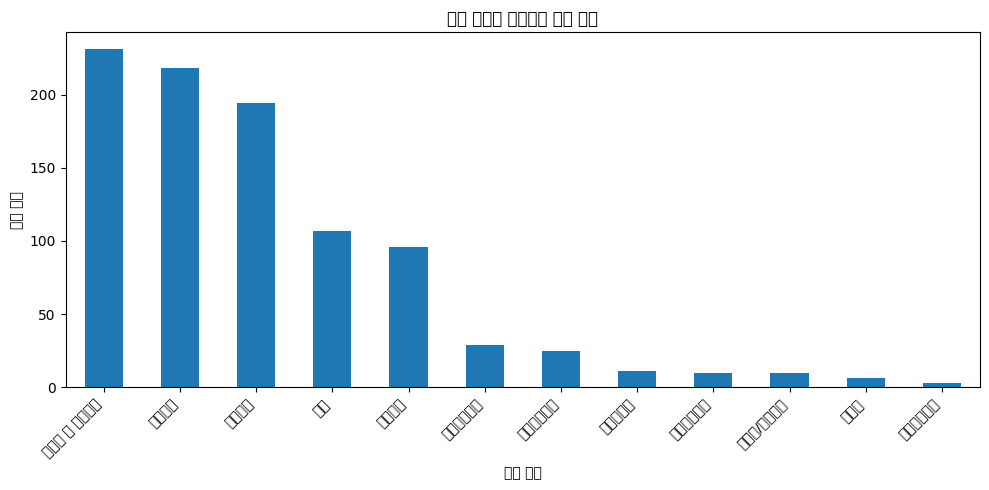

In [ ]:
category_col = '공간 구분 이름'
category_counts = data[category_col].value_counts()

display(category_counts.to_frame('기록 건수'))

plt.figure(figsize=(10, 5))
category_counts.plot(kind='bar')
plt.title('공간 구분별 문화공간 기록 건수')
plt.xlabel('공간 구분')
plt.ylabel('기록 건수')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. 질문 2. 공간 구분별 전화번호 결측률은 어떻게 다를까?

,전화번호 결측률(%)
공간 구분 이름,
개인문화시설,0.0
공연시설,10.3
기타,55.1
도서관 및 지역서점,2.2
문화복지시설,0.0
문화원/전수회관,10.0
생활문화공간,16.0
영화관,0.0
전시시설,8.3


/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 52404 (\N{HANGUL SYLLABLE CE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 50977 (\N{HANGUL SYLLABLE YUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/826271046.py:14: UserWarning: Glyph 52397 (\N{HANGUL SYLLABLE CEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ip

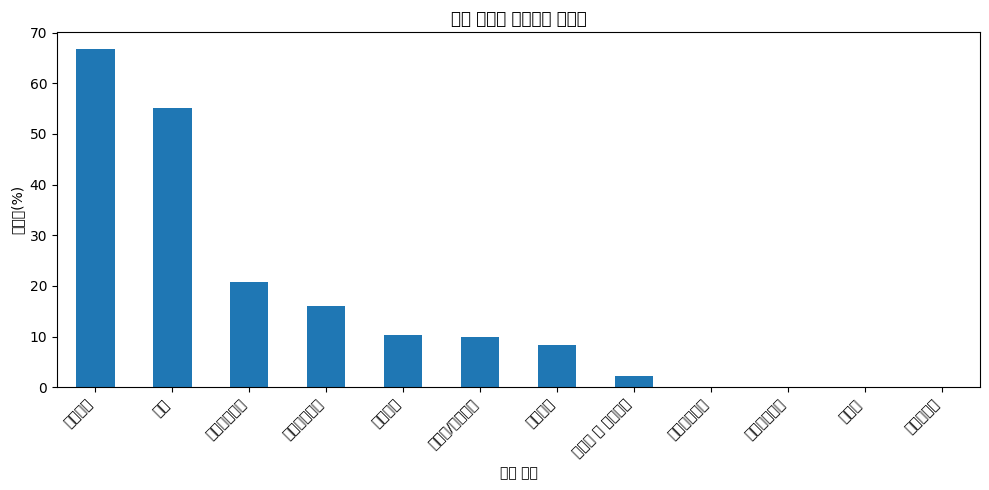

전체 전화번호 결측: 177 건


In [ ]:
phone_col = '전화번호'
phone_missing = data.groupby(category_col)[phone_col].apply(
    lambda x: x.isna().mean() * 100
).round(1)

display(phone_missing.to_frame('전화번호 결측률(%)'))

plt.figure(figsize=(10, 5))
phone_missing.sort_values(ascending=False).plot(kind='bar')
plt.title('공간 구분별 전화번호 결측률')
plt.xlabel('공간 구분')
plt.ylabel('결측률(%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('전체 전화번호 결측:', int(data[phone_col].isna().sum()), '건')

## 4. 질문 3. 어떤 항목에 빈칸이 가장 많이 있을까?

,결측치 개수
번호,0
공간 구분 이름,0
공간명,0
전화번호,177
팩스번호,538
주소,5
상세주소,696


/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 48264 (\N{HANGUL SYLLABLE BEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_787/2413599282.py:10: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

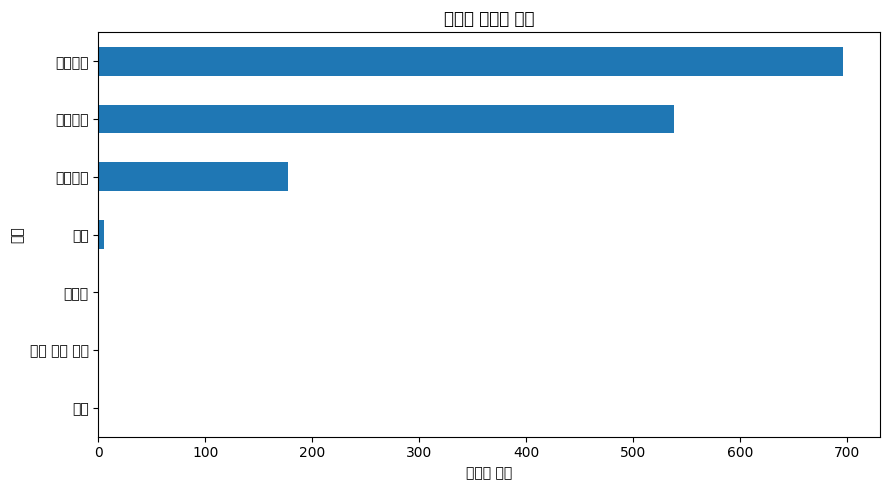

In [ ]:
missing_counts = data.isna().sum()

display(missing_counts.to_frame('결측치 개수'))

plt.figure(figsize=(9, 5))
missing_counts.sort_values().plot(kind='barh')
plt.title('항목별 결측치 개수')
plt.xlabel('결측치 개수')
plt.ylabel('항목')
plt.tight_layout()
plt.show()

## 5. 분석 결과 요약

In [ ]:
print('총 기록 수:', len(data))
print('총 열 수:', data.shape[1])
print('완전히 같은 행:', int(data.duplicated().sum()))
print('항목별 결측치 수')
display(data.isna().sum().to_frame('결측치 수'))

print('주의: CSV에 기록된 건수만 분석했으며, 실제 운영 시설 수나 시민 이용량을 뜻한다고 단정할 수 없습니다.')

총 기록 수: 940
총 열 수: 7
완전히 같은 행: 0
항목별 결측치 수


,결측치 수
번호,0
공간 구분 이름,0
공간명,0
전화번호,177
팩스번호,538
주소,5
상세주소,696


주의: CSV에 기록된 건수만 분석했으며, 실제 운영 시설 수나 시민 이용량을 뜻한다고 단정할 수 없습니다.
